# Application of QMCCBO: A two-dimensional data-driven model for traffic flow in highways

### Data Set: Vehicle Trajectory Dataset from Heidelberg

#### Data preperation

In [5]:
from scipy.io import loadmat
import numpy as np
import matplotlib.pyplot as plt
import torch
import pandas as pd
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.patches import Rectangle, ConnectionPatch


mat = loadmat('data/HD_TrafficData_2025_01.mat', simplify_cells=True)
data = mat['results']

"""
The data consists of a list with dictionaries, each containing the following information:
'id'                        : Unique identifier of the traffic sensor.
'description'               : Location, driving direction, and (if applicable) lane of the traffic sensor.
'dates'                     : Timestamps of all processed measurements (datetime vector).
'trafficCount'              : Number of vehicles counted in each 15-minute interval (vector).
'averageSpeed'              : Mean vehicle speed in each 15-minute interval [km/h] (vector).
'trafficCountDay'           : Traffic counts reshaped into a matrix with 96 rows (15-minute intervals) and one column per day.
'averageSpeedDay'           : Average speeds reshaped into a matrix with 96 rows (15-minute intervals) and one column per day.
'meanTrafficCount_intraday' : Average traffic count for each 15-minute interval over a typical day (96 values).
'meanAverageSpeed_intraday' : Average speed for each 15-minute interval over a typical day (96 values).
'meanTrafficCount_daily'    : Average daily traffic count for each day in the dataset.
'meanAverageSpeed_daily'    : Average daily vehicle speed for each day in the dataset.
"""

# print all descriptions, from which we can choose data
for i, detector in enumerate(data):
    print(f"{i:2d}: {detector['description']}")

 0: Cuzaring-Stueckerweg-inbound-singleLane
 1: B535-L600a-Grasweg-inbound-rightLane
 2: B535-L600a-Grasweg-inbound-leftLane
 3: SpeyererStrasse-ImMoergelgewann-Outbound-leftLane
 4: SpeyererStrasse-ImMoergelgewann-Outbound-rightLane
 5: B535-L600a-Grasweg-inbound-rightLane
 6: BerlinerStrasse-ImNeuenheimerFeld-inbound-leftLane
 7: SpeyererStrasse-ImMoergelgewann-inbound-leftLane
 8: BerlinerStrasse-ImNeuenheimerFeld-Outbound-leftLane
 9: SpeyererStrasse-ImMoergelgewann-inbound-rightLane
10: SpeyererStrasse-ImMoergelgewann-inbound-rightLane
11: Bismarckplatz-RohrbacherStrasse-BergheimerStrasse-inbound-middleLane
12: Bismarckplatz-RohrbacherStrasse-BergheimerStrasse-Outbound-rightHandTurningLane
13: BerlinerStrasse-ImNeuenheimerFeld-inbound-rightLane
14: Cuzaring-Stueckerweg-inbound-singleLane
15: BerlinerStrasse-ImNeuenheimerFeld-Outbound-rightLane
16: BerlinerStrasse-ImNeuenheimerFeld-inbound-rightLane
17: B535-L600a-Grasweg-inbound-leftLane
18: Bismarckplatz-RohrbacherStrasse-Berghei

C:\Users\jheieck\AppData\Local\Temp\ipykernel_11788\295944163.py:5: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


In [6]:
# extract desired traffic data
# description = "Cuzaring-Stueckerweg-inbound-singleLane"
description = "BerlinerStrasse-ImNeuenheimerFeld-inbound-leftLane"
detector = next((d for d in data if d["description"] == description), None)

traffic_count = detector["trafficCount"].astype(float)
average_speed = detector["averageSpeed"].astype(float) 

# determine average velocity and flux (trafficCount contains the number of vehicles per 15-minute interval)
q = 4 * traffic_count  # flux [vehicle/h]
u = average_speed  # average speed [km/h]

# determine moving mean of density, flux and average velocity
window_value = 4   # number of 15-minute intervals
q_data = pd.Series(q).rolling(window=window_value, min_periods=window_value).mean()
u_data = pd.Series(u).rolling(window=window_value, min_periods=window_value).mean()

# neglect non-numerical values
mask = (q_data.notna() & u_data.notna())
q_data = q_data[mask]
u_data = u_data[mask]
rho_data = q_data / u_data

# transform to torch tensors for (QMC)CBO application
rho_torch = torch.tensor(rho_data.to_numpy(), dtype=torch.float32)
q_torch = torch.tensor(q_data.to_numpy(), dtype=torch.float32)
u_torch = torch.tensor(u_data.to_numpy(), dtype=torch.float32)

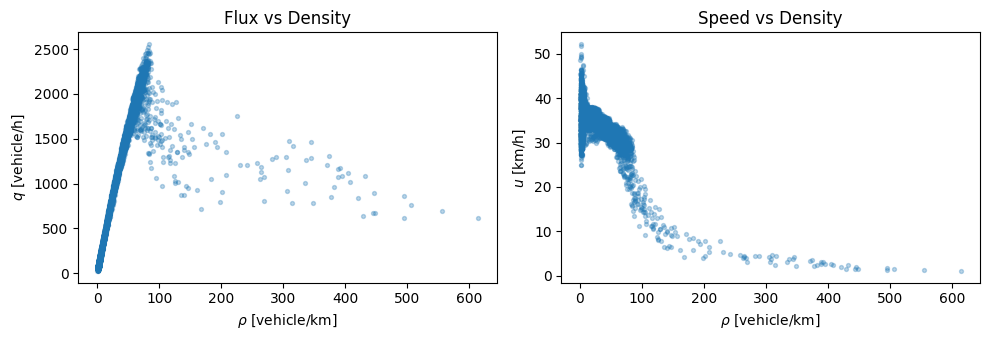

In [7]:
# Plot fundamental diagrams
fig, ax = plt.subplots(1, 2, figsize=(10,3.5))

# Flux 
ax[0].scatter(rho_data, q_data, s=8, alpha=0.3)
ax[0].set_title("Flux vs Density")
ax[0].set_xlabel(r"$\rho$ [vehicle/km]")
ax[0].set_ylabel(r"$q$ [vehicle/h]")

# Speed
ax[1].scatter(rho_data, u_data, s=8, alpha=0.3)
ax[1].set_title("Speed vs Density")
ax[1].set_xlabel(r"$\rho$ [vehicle/km]")
ax[1].set_ylabel(r"$u$ [km/h]")

plt.tight_layout()
plt.savefig("images/fundamental_diagrams_heidelberg.png", dpi=300, bbox_inches="tight")
plt.show()

### Model and objective functions

In [8]:
number_lanes = 1  # number of lanes without off-ramp
rho_max = number_lanes / 7.5 * 1000  # maxmial density [vehicle/km]

# Model functions 

# Scipy optimization
# INPUT: - alpha (scalar): alpha parameter
#        - lam (scalar): lambda parameter
#        - p (scalar): p parameter
#        - rho (1xM numpy-vector): density rho for any obersvation (data point)
# OUTPUT: - prediction (1xM numpy-vector): approximated flux for model parameter combination and observed data point (column)
def q_model_numpy(rho, alpha, lam, p):

    d1 = np.sqrt(1 + (lam*p)**2)
    d2 = np.sqrt(1 + (lam*(1-p))**2)
    d3 = lam*(rho/rho_max - p)
    return alpha*(d1 + (d2-d1)*(rho/rho_max) - np.sqrt(1 + d3**2))

# (QMC)CBO 
# INPUT: - alpha (Nx1 torch-tensor): alpha parameters for all particles
#        - lam (Nx1 torch-tensor): lambda parameters for all particles
#        - p (Nx1 torch-tensor): p parameters for all particles
#        - rho (1xM torch-tensor): density rho for any obersvation (data point)
# OUTPUT: - prediction (NxM torch-tensor): approximated flux for any model parameter combination (row) and observed data point (column)
def q_model_torch(alpha, lam, p, rho):

    d1 = torch.sqrt(1 + (lam*p)**2)  # torch-tensor size Nx1
    d2 = torch.sqrt(1 + (lam*(1-p))**2)  # torch-tensor size Nx1
    d3 = lam*(rho/rho_max - p)  # broadcasting: Nx1 * (1xM/1x1 - Nx1) = NxM
    return alpha * (d1 + (d2-d1)*(rho/rho_max) - torch.sqrt(1 + d3**2))  # broadcasting: Nx1 * ( Nx1 + Nx1 * 1xM) - NxM )


# Objective functions

# Scipy optimization
# INPUT : - theta ((3) numpy-vector): describing three modelparameters
# OUTPUT : - scalar: describes the loss for theta model parameters
def objective_numpy(theta):
    alpha, lam, p = theta
    q_fit = q_model_numpy(rho_data, alpha, lam, p)
    return np.sum((q_data - q_fit)**2)

# (QMC)CBO
# INPUT : - V ((N x 3)-torch-matrix): describing three modelparameters for each particle/model parameter configuration
# OUTPUT : - V_prime ((1xN)-torch-matrix): describes the loss for each model parameter configuration
def objective_torch(V):
    # Extract model parameters from V columnwise to torch tensor of size 1xM
    alpha = V[:, 0:1]
    lam = V[:, 1:2]
    p = V[:, 2:3]

    # transforms data into torch tensor of size 1xM to match model parameters dimension
    rho = rho_torch[None, :]
    qx = q_torch[None, :]

    qx_prediction = q_model_torch(alpha, lam, p, rho)
    return torch.sum((qx_prediction - qx)**2, dim=1)

### Data Fitting

In [9]:
from scipy.optimize import minimize
from scipy.optimize import differential_evolution
from optimization import CBO
from optimization import QMCCBO_base2
from torch.distributions import Uniform
from IPython.display import display, Math
import time

Nelder-Mead (Simplex)

In [10]:
# initial simplex
initial_simplex = np.array([
    [100, 1, -20],   # initial guess
    [300, 1, -20],   # variation in alpha
    [100, -200, -20],   # variation in lambda
    [100, 1, 400]    # variation in p
])
function_value = 1e-6

# Model prediction
start_time = time.perf_counter()
result_simplex = minimize(objective_numpy, x0=initial_simplex[0], method="Nelder-Mead", bounds=[(-500,500), (-500,500), (-500,500)], options={"initial_simplex": initial_simplex, "fatol": function_value,  "maxfev": 2048,  "maxiter": 1300})
end_time = time.perf_counter()
time_simplex = end_time - start_time
alpha_simplex, lambda_simplex, p_simplex = result_simplex.x

print("Iterations:", result_simplex.nit)
print("Function evaluations:", result_simplex.nfev)
print("Success:", result_simplex.success)
print("Message:", result_simplex.message)

Iterations: 955
Function evaluations: 1628
Success: True
Message: Optimization terminated successfully.


In [11]:
display(Math(
    rf"\text{{Model parameters with Nelder-Mead}}:\;"
    rf"\alpha = {alpha_simplex:.4f},\;"
    rf"\lambda = {lambda_simplex:.4f},\;"
    rf"p = {p_simplex:.4f}\;"
    rf"\text{{time}} = {time_simplex:.2f}\,\text{{s}}\;"
    rf"\text{{function evaluations}} = {result_simplex.nfev}"
))

<IPython.core.display.Math object>

L-BFGS-B

In [80]:
# Model prediction
start_time = time.perf_counter()
result_lbfgs = minimize(objective_numpy, x0=[10, 100, 0], method="L-BFGS-B", bounds=[(-500,500), (-500,500), (-500,500)], options={"maxiter": 400, "maxfun": 2048, "ftol": function_value, "maxcor": 10})
end_time = time.perf_counter()
time_lbfgs = end_time - start_time
alpha_lbfgs, lambda_lbfgs, p_lbfgs = result_lbfgs.x

print("Iterations:", result_lbfgs.nit)
print("Function evaluations:", result_lbfgs.nfev)
print("Success:", result_lbfgs.success)
print("Message:", result_lbfgs.message)

Iterations: 11
Function evaluations: 92
Success: True
Message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH


In [81]:
display(Math(
    rf"\text{{Model parameters in x-direction with L-BFGS-R}}:\;"
    rf"\alpha = {alpha_lbfgs:.4f},\;"
    rf"\lambda = {lambda_lbfgs:.4f},\;"
    rf"p = {p_lbfgs:.4f}\;"
    rf"\text{{time}} = {time_lbfgs:.2f}\,\text{{s}}\;"
    rf"\text{{function evaluations}} = {result_lbfgs.nfev}"
))

<IPython.core.display.Math object>

Differential Evolution

In [78]:
# Model prediction
start_time = time.perf_counter()
result_de = differential_evolution(objective_numpy, bounds=[(-500,500), (-500,500), (-500,500)], tol=function_value, maxiter=44, init='random', updating='deferred', polish=False) #fev_max = 1980 = 15 * 3 * 2 * 11 = popsize * number params * 2 * max_iter)
end_time = time.perf_counter()
time_de = end_time - start_time
alpha_de, lambda_de, p_de = result_de.x

print("Iterations:", result_de.nit)
print("Function evaluations:", result_de.nfev)
print("Success:", result_de.success)
print("Message:", result_de.message)

Iterations: 44
Function evaluations: 2025
Success: False
Message: Maximum number of iterations has been exceeded.


In [79]:
display(Math(
    rf"\text{{Model parameters with Differential Evolution}}:\;"
    rf"\alpha = {alpha_de:.4f},\;"
    rf"\lambda = {lambda_de:.4f},\;"
    rf"p = {p_de:.4f}\;"
    rf"\text{{time}} = {time_de:.2f}\,\text{{s}}\;"
    rf"\text{{function evaluations}} = {result_de.nfev}"
))

<IPython.core.display.Math object>

CBO

In [67]:
# set input for (QMC)CBO
dimensionality = 3  # dimension of the problem
n_particles = 11  # number of agents 2^n_particles
dt = 0.05  # step size of discretization
l = 1  # lambda (drift paramter)
sigma = 1
alpha = 100  # alpha (consensus weight)
n_particles_batches = 1  # batch size of each batch
epochs = 100  # number of iteration od SDE solution scheme (M)
batch_size = None
time_horizon = None

In [68]:
# set input for cbo
initial_distribution = Uniform(-500,500)  # initial distribution function
SDE_method = 'Euler_Maruyama'  # SDE solution scheme
anisotropic = False  # anisotropic CBO

# Model prediction
start_time = time.perf_counter()
result_CBO = CBO.minimize(
        objective_torch, dimensionality, 2**n_particles, initial_distribution, dt, l, sigma, 
        alpha, anisotropic, SDE_method, batch_size, n_particles_batches, epochs, time_horizon,
        use_partial_update=False, use_additional_random_shift=False, use_additional_gradients_shift=False,
        random_shift_epsilon=None, gradients_shift_gamma=None,
        best_particle_alpha=1e5, use_gpu_if_available=False, return_trajectory=False, cooling=False
    )
end_time = time.perf_counter()
time_CBO = end_time - start_time

alpha_CBO, lambda_CBO, p_CBO = np.clip(result_CBO.numpy(), -500, 500)
# alpha_CBO, lambda_CBO, p_CBO = result_CBO.numpy()

In [69]:
display(Math(
    rf"\text{{Model parameters with Differential Evolution}}:\;"
    rf"\alpha = {alpha_CBO:.4f},\;"
    rf"\lambda = {lambda_CBO:.4f},\;"
    rf"p = {p_CBO:.4f}\;"
    rf"\text{{time}} = {time_CBO:.2f}\,\text{{s}}\;"
    rf"\text{{function evaluations}} = {2 ** n_particles}"
))

<IPython.core.display.Math object>

QMCCBO

In [65]:
# set input for QMCCBO
K = 500  # radius of cube
x_est = np.array([0,0,0])  # estimation of minimizer
ODE_method = 'Euler'  # SDE solution scheme 
theta = 0

# Model prediction
start_time = time.perf_counter()
result_QMCCBO = QMCCBO_base2.minimize(
        objective_torch, dimensionality, n_particles, K, x_est, dt, l, alpha, 
        ODE_method, theta, batch_size, n_particles_batches, epochs, time_horizon,
        use_partial_update=False, use_additional_gradients_shift=False, gradients_shift_gamma=None,
        best_particle_alpha=1e5, use_gpu_if_available=False, return_trajectory=False, cooling=False)
end_time = time.perf_counter()
time_QMCCBO = end_time - start_time

alpha_QMCCBO, lambda_QMCCBO, p_QMCCBO = result_QMCCBO.numpy()

In [66]:
display(Math(
    rf"\text{{Model parameters with CBO}}:\;"
    rf"\alpha^x = {alpha_QMCCBO:.4f},\;"
    rf"\lambda^x = {lambda_QMCCBO:.4f},\;"
    rf"p^x = {p_QMCCBO:.4f},\;"
    rf"\text{{time}} = {time_QMCCBO:.2f}\,\text{{s}}\;"
    rf"\text{{function evaluations}} = {2 ** n_particles}"
))

<IPython.core.display.Math object>

### Compare all models with data

In [83]:
# compute fitted data
rho_plot = np.linspace(rho_data.min(), rho_data.max(), 1000)

# Nelder-Mead
q_fit_simplex = q_model_numpy(rho_plot, alpha_simplex, lambda_simplex, p_simplex)
u_fit_simplex = q_fit_simplex / np.maximum(rho_plot, 1e-6)

#L-BFGS-R
q_fit_lbfgs = q_model_numpy(rho_plot, alpha_lbfgs, lambda_lbfgs, p_lbfgs)
u_fit_lbfgs = q_fit_lbfgs / np.maximum(rho_plot, 1e-6)

# Differential Evolution
q_fit_de = q_model_numpy(rho_plot, alpha_de, lambda_de, p_de)
u_fit_de = q_fit_de / np.maximum(rho_plot, 1e-6)

# CBO
q_fit_CBO = q_model_numpy(rho_plot, alpha_CBO, lambda_CBO, p_CBO)
u_fit_CBO = q_fit_CBO / np.maximum(rho_plot, 1e-6)

# QMCCBO
q_fit_QMCCBO = q_model_numpy(rho_plot, alpha_QMCCBO, lambda_QMCCBO, p_QMCCBO)
u_fit_QMCCBO = q_fit_QMCCBO / np.maximum(rho_plot, 1e-6)

In [84]:
# zoom function
data_color = "#9e9898"

lw_main = 3
lw_other = 3
alpha_data = 0.22

def add_zoom(ax, xlim, ylim, bbox=None, width="35%", height="35%", loc="upper right", show_scatter=True,
             rect_corners=None, inset_corners=((0,1),(1,0)), rectangle_kwargs=None, connection_kwargs=None):

    # default for lines connectiong the boxes
    if rectangle_kwargs is None:
        rectangle_kwargs = dict(edgecolor="black", facecolor="none", linewidth=1.2, linestyle="--", zorder=100)
    if connection_kwargs is None:
        connection_kwargs = dict(color="black", linewidth=1.0, linestyle="--", zorder=100)

    # Zoomed window
    if bbox is None:
        axins = inset_axes(ax, width=width, height=height, loc=loc)
    else:
        axins = inset_axes(ax, width="100%", height="100%", bbox_to_anchor=bbox, bbox_transform=ax.transAxes, loc="lower left", borderpad=0)

    # copy lines in zoomed window
    for line in ax.get_lines():
        axins.plot(line.get_xdata(), line.get_ydata(), color=line.get_color(), linestyle=line.get_linestyle(), linewidth=line.get_linewidth())

    # copy scatter in zoomed window
    if show_scatter:
        for coll in ax.collections:
            offsets = coll.get_offsets()
            axins.scatter(offsets[:,0], offsets[:,1], s=coll.get_sizes(), color=coll.get_facecolor(), alpha=coll.get_alpha())

    # which section shall be zooomed
    axins.set_xlim(*xlim)
    axins.set_ylim(*ylim)
    axins.set_xticks([])
    axins.set_yticks([])

    # set rectangle, which gets zoomed
    if rect_corners is None:
        rect_corners = ((xlim[0], ylim[1]), (xlim[1], ylim[0]))
    (p1, p2) = rect_corners
    xmin = min(p1[0], p2[0])
    xmax = max(p1[0], p2[0])
    ymin = min(p1[1], p2[1])
    ymax = max(p1[1], p2[1])
    rectangle = Rectangle((xmin, ymin), xmax-xmin, ymax-ymin, **rectangle_kwargs)
    ax.add_patch(rectangle)

    # Connecting lines
    (q1, q2) = inset_corners
    con1 = ConnectionPatch(xyA=p1, coordsA=ax.transData, xyB=q1, coordsB=axins.transAxes, **connection_kwargs)
    con2 = ConnectionPatch(xyA=p2, coordsA=ax.transData, xyB=q2, coordsB=axins.transAxes, **connection_kwargs)
    ax.add_artist(con1)
    ax.add_artist(con2)

    # zoom domain and zoom box identical if not specified
    if rect_corners is None:
        rect_corners = ((xlim[0], ylim[0]), (xlim[1], ylim[1]))

    return axins

C:\Users\jheieck\AppData\Local\Temp\ipykernel_11788\1828276714.py:30: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


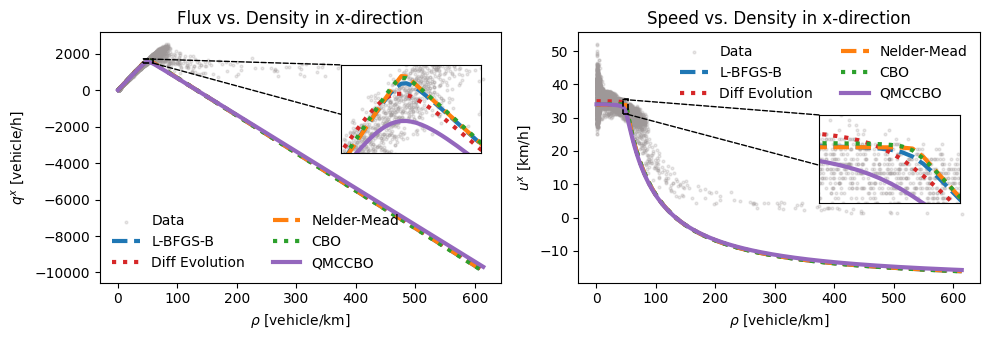

In [93]:
# plotting fundamental diagrams with fitted models
fig, ax = plt.subplots(1, 2, figsize=(10,3.5))

# Flux
ax[0].scatter(rho_data, q_data, s=4, alpha=alpha_data, color=data_color, label="Data")
ax[0].plot(rho_plot, q_fit_lbfgs, color="#1f77b4", linewidth=lw_main, linestyle="--", label="L-BFGS-B")
ax[0].plot(rho_plot, q_fit_de, color="#d62728", linewidth=lw_other, linestyle=":", label="Diff Evolution")
ax[0].plot(rho_plot, q_fit_simplex, color="#ff7f0e", linewidth=lw_other, linestyle="--", label="Nelder-Mead")
ax[0].plot(rho_plot, q_fit_CBO, color="#2ca02c", linewidth=lw_other, linestyle=":", label="CBO")
ax[0].plot(rho_plot, q_fit_QMCCBO, color="#9467bd", linewidth=lw_other, label="QMCCBO")
ax[0].set_title("Flux vs. Density in x-direction")
ax[0].set_xlabel(r"$\rho$ [vehicle/km]")
ax[0].set_ylabel(r"$q^x$ [vehicle/h]")
ax[0].legend(fontsize=10, ncol=2, frameon=False)
add_zoom(ax[0], xlim=(43,60), ylim=(1490,1730), bbox=(0.60,0.52,0.35,0.35), inset_corners=((0,1), (1,0))) # Zoom

# Speed
ax[1].scatter(rho_data, u_data, s=4, alpha=alpha_data, color=data_color, label="Data")
ax[1].plot(rho_plot, u_fit_lbfgs, color="#1f77b4", linewidth=lw_main, linestyle="--", label="L-BFGS-B")
ax[1].plot(rho_plot, u_fit_de, color="#d62728", linewidth=lw_other, linestyle=":", label="Diff Evolution")
ax[1].plot(rho_plot, u_fit_simplex, color="#ff7f0e", linewidth=lw_other, linestyle="--", label="Nelder-Mead")
ax[1].plot(rho_plot, u_fit_CBO, color="#2ca02c", linewidth=lw_other, linestyle=":", label="CBO")
ax[1].plot(rho_plot, u_fit_QMCCBO, color="#9467bd", linewidth=lw_other, label="QMCCBO")
ax[1].set_title("Speed vs. Density in x-direction")
ax[1].set_xlabel(r"$\rho$ [vehicle/km]")
ax[1].set_ylabel(r"$u^x$ [km/h]")
ax[1].legend(fontsize=10, ncol=2, frameon=False)
add_zoom(ax[1], xlim=(45,53), ylim=(31,35.5), bbox=(0.60,0.32,0.35,0.35), inset_corners=((0,1), (1,0))) # Zoom

plt.tight_layout()
plt.savefig("images/fundamental_diagrams_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

C:\Users\jheieck\AppData\Local\Temp\ipykernel_11788\2768545478.py:17: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


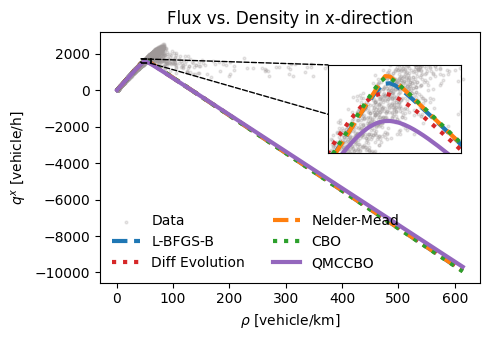

In [97]:
# plotting fundamental diagrams with fitted models
fig, ax = plt.subplots(1, 1, figsize=(5,3.5))

# Flux
ax.scatter(rho_data, q_data, s=4, alpha=alpha_data, color=data_color, label="Data")
ax.plot(rho_plot, q_fit_lbfgs, color="#1f77b4", linewidth=lw_main, linestyle="--", label="L-BFGS-B")
ax.plot(rho_plot, q_fit_de, color="#d62728", linewidth=lw_other, linestyle=":", label="Diff Evolution")
ax.plot(rho_plot, q_fit_simplex, color="#ff7f0e", linewidth=lw_other, linestyle="--", label="Nelder-Mead")
ax.plot(rho_plot, q_fit_CBO, color="#2ca02c", linewidth=lw_other, linestyle=":", label="CBO")
ax.plot(rho_plot, q_fit_QMCCBO, color="#9467bd", linewidth=lw_other, label="QMCCBO")
ax.set_title("Flux vs. Density in x-direction")
ax.set_xlabel(r"$\rho$ [vehicle/km]")
ax.set_ylabel(r"$q^x$ [vehicle/h]")
ax.legend(fontsize=10, ncol=2, frameon=False)
add_zoom(ax, xlim=(43,60), ylim=(1490,1730), bbox=(0.60,0.52,0.35,0.35), inset_corners=((0,1), (1,0))) # Zoom

plt.tight_layout()
plt.savefig("images/fundamental_diagrams_comparison_compact.png", dpi=300, bbox_inches="tight")
plt.show()

In [89]:
q_fit_de_at_data = q_model_numpy(rho_data, alpha_de, lambda_de, p_de)
q_fit_simplex_at_data = q_model_numpy(rho_data, alpha_simplex, lambda_simplex, p_simplex)
q_fit_lbfgs_at_data = q_model_numpy(rho_data, alpha_lbfgs, lambda_lbfgs, p_lbfgs)
q_fit_CBO_at_data = q_model_numpy(rho_data, alpha_CBO, lambda_CBO, p_CBO)
q_fit_QMCCBO_at_data = q_model_numpy(rho_data, alpha_QMCCBO, lambda_QMCCBO, p_QMCCBO)

err_q_de = np.linalg.norm(q_data - q_fit_de_at_data) / np.linalg.norm(q_data)
err_q_simplex = np.linalg.norm(q_data - q_fit_simplex_at_data) / np.linalg.norm(q_data)
err_q_lbfgs = np.linalg.norm(q_data - q_fit_lbfgs_at_data) / np.linalg.norm(q_data)
err_q_CBO = np.linalg.norm(q_data - q_fit_CBO_at_data) / np.linalg.norm(q_data)
err_q_QMCCBO = np.linalg.norm(q_data - q_fit_QMCCBO_at_data) / np.linalg.norm(q_data)

print("Relative L2-errors for qx:\n")

print(f"Differential Evolution : {err_q_de:.6e}    | time = {time_de:.2f} s")
print(f"Nelder-Mead            : {err_q_simplex:.6e}    | time = {time_simplex:.2f} s")
print(f"L-BFGS-B               : {err_q_lbfgs:.6e}    | time = {time_lbfgs:.2f} s")
print(f"CBO                    : {err_q_CBO:.6e}    | time = {time_CBO:.2f} s")
print(f"QMCCBO                 : {err_q_QMCCBO:.6e}    | time = {time_QMCCBO:.2f} s")

Relative L2-errors for qx:

Differential Evolution : 4.351822e-01    | time = 4.40 s
Nelder-Mead            : 4.341672e-01    | time = 3.82 s
L-BFGS-B               : 4.342936e-01    | time = 0.14 s
CBO                    : 4.342247e-01    | time = 13.55 s
QMCCBO                 : 4.369821e-01    | time = 22.75 s


### Monte-Carlo approximation of error

In [38]:
# define function, that runs all stochastic optimization algorithms
def run_all_methods_once():

    # L-BFGS-B
    a_lb, l_lb, p_lb = minimize(objective_numpy, x0=[10,10,10], method="L-BFGS-B", bounds=[(-500,500)]*3, options={"maxiter": 400}).x

    # Differential Evolution
    a_de, l_de, p_de = differential_evolution(objective_numpy, bounds=[(-500,500)]*3, maxiter=22).x

    # CBO
    res_cbo = CBO.minimize(
        objective_torch, dimensionality, 2**n_particles, initial_distribution, dt, l, sigma, 
        alpha, anisotropic, SDE_method, batch_size, n_particles_batches, epochs, time_horizon,
        use_partial_update=False, use_additional_random_shift=False, use_additional_gradients_shift=False,
        random_shift_epsilon=None, gradients_shift_gamma=None,
        best_particle_alpha=1e5, use_gpu_if_available=False, return_trajectory=False, cooling=False)
    a_cbo, l_cbo, p_cbo = res_cbo.numpy()

    # errors
    q_de = np.linalg.norm(q_data - q_model_numpy(rho_data, a_de, l_de, p_de)) / np.linalg.norm(q_data)
    q_lb = np.linalg.norm(q_data - q_model_numpy(rho_data, a_lb, l_lb, p_lb)) / np.linalg.norm(q_data)
    q_cbo = np.linalg.norm(q_data - q_model_numpy(rho_data, a_cbo, l_cbo, p_cbo)) / np.linalg.norm(q_data)

    return {
        "q": [q_de, q_lb, q_cbo],
    }


In [ ]:
n_mc = 1000

errors = []

for i in range(n_mc):
    res = run_all_methods_once()
    errors.append(res["qx"])

errors = np.array(errors)

In [ ]:
print("\nMean Relative L2-errors (Monte Carlo):\n")

# Differential Evolution
mean = errors[:, 0].mean()
std  = errors[:, 0].std()
print(f"{'Diff Evo':<12} | {mean:.4e} ± {std:.2e} ")

# Nelder-Mead (deterministic)
print(f"{'Nelder-Mead':<12} | " f"{err_q_simplex:.4e} ± {0.0:.2e}")

# L-BFGS-B
mean = errors[:, 1].mean()
std  = errors[:, 1].std()
print(f"{'L-BFGS-B':<12} | {mean:.4e} ± {std:.2e}")

# CBO
mean = errors[:, 2].mean()
std  = errors[:, 2].std()
print(f"{'CBO':<12} |{mean:.4e} ± {std:.2e}")

# QMCCBO (deterministic)
print(f"{'QMCCBO':<12} | " f"x: {err_q_QMCCBO:.4e} ± {0.0:.2e}")


Mean Relative L2-errors (Monte Carlo):

Diff Evo     | x: 6.0268e-01 ± 4.25e-01   | y: 6.7169e-01 ± 3.69e-01
Nelder-Mead  | x: 5.6497e-02 ± 0.00e+00   | y: 1.8670e-01 ± 0.00e+00
L-BFGS-B     | x: 5.7622e-02 ± 2.08e-17   | y: 1.8639e-01 ± 2.78e-17
CBO          | x: 1.3972e-01 ± 1.90e-01   | y: 3.2221e+02 ± 7.50e+01
QMCCBO       | x: 6.9190e-02 ± 0.00e+00   | y: 2.3901e-01 ± 0.00e+00
